In [1]:
# Bỏ dấu # nếu môi trường chưa có thư viện:
# %pip install pandas numpy scikit-learn matplotlib
import time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
try:
    from IPython.display import display
except ImportError:
    display = print
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, classification_report, ConfusionMatrixDisplay)
RANDOM_STATE = 42

## 1. Đọc và kiểm tra dữ liệu


In [2]:
DATA_PATH = Path("C:/Users/thanh/Desktop/Machine Learning/kaggle/Titanic-EDA/data/train.csv")  
if not DATA_PATH.exists():
    candidates = sorted(Path('/kaggle/input').rglob('train.csv')) if Path('/kaggle/input').exists() else []
    if len(candidates) == 1:
        DATA_PATH = candidates[0]
    else:
        raise FileNotFoundError('Hãy đặt train.csv cạnh notebook hoặc sửa DATA_PATH tới file Titanic train.csv.')
df = pd.read_csv(DATA_PATH)
required = ['Survived', 'Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked']
missing_columns = set(required) - set(df.columns)
if missing_columns:
    raise ValueError(f'Thiếu cột: {missing_columns}. Hãy chọn dữ liệu Titanic train.csv.')
if df['Survived'].isna().any() or not set(df['Survived'].unique()).issubset({0, 1}):
    raise ValueError('Survived phải có nhãn 0/1 và không được thiếu.')
print('Kích thước:', df.shape)
print('Số dòng trùng toàn bộ:', df.duplicated().sum())
display(df.head())
display(df[required].isna().sum().rename('Số giá trị thiếu').to_frame())
display(df['Survived'].value_counts().sort_index().rename('Số hành khách').to_frame())

Kích thước: (891, 12)
Số dòng trùng toàn bộ: 0


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


,Số giá trị thiếu
Survived,0
Pclass,0
Sex,0
Age,177
SibSp,0
Parch,0
Fare,0
Embarked,2


,Số hành khách
Survived,
0,549
1,342


## 2. Chọn đặc trưng và chia dữ liệu


In [3]:
numeric_features = ['Age', 'SibSp', 'Parch', 'Fare']
categorical_features = ['Pclass', 'Sex', 'Embarked']
features = numeric_features + categorical_features
X = df[features].copy()
y = df['Survived'].astype(int)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)
print('Train:', X_train.shape, '| Test:', X_test.shape)
preprocessor = ColumnTransformer([
    ('num', SimpleImputer(strategy='median'), numeric_features),
    ('cat', Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('onehot', OneHotEncoder(handle_unknown='ignore'))
    ]), categorical_features)
])

Train: (712, 7) | Test: (179, 7)


## 3. Xây dựng hai mô hình


In [4]:
models = {
    'Decision Tree': Pipeline([
        ('preprocess', clone(preprocessor)),
        ('model', DecisionTreeClassifier(
            criterion='gini', max_depth=4, min_samples_leaf=5,
            random_state=RANDOM_STATE))
    ]),
    'Random Forest': Pipeline([
        ('preprocess', clone(preprocessor)),
        ('model', RandomForestClassifier(
            n_estimators=200, max_depth=8, min_samples_leaf=2,
            max_features='sqrt', bootstrap=True, n_jobs=-1,
            random_state=RANDOM_STATE))
    ])
}
# Cross-validation chỉ trên tập train; test được giữ riêng để đánh giá cuối.
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_results = {}
for name, model in models.items():
    scores = cross_val_score(model, X_train, y_train, cv=cv, scoring='accuracy')
    cv_results[name] = (scores.mean(), scores.std())
    print(f'{name}: CV accuracy = {scores.mean():.4f} ± {scores.std():.4f}')
# Chọn mô hình dựa trên CV trước khi xem kết quả test.
selected_name = max(cv_results, key=lambda name: cv_results[name][0])
print('Mô hình được chọn theo CV:', selected_name)

Decision Tree: CV accuracy = 0.8118 ± 0.0133
Random Forest: CV accuracy = 0.8146 ± 0.0314
Mô hình được chọn theo CV: Random Forest


## 4. Huấn luyện và đánh giá



Decision Tree
                precision    recall  f1-score   support

Khong song sot       0.77      0.92      0.83       110
      Song sot       0.81      0.55      0.66        69

      accuracy                           0.78       179
     macro avg       0.79      0.73      0.74       179
  weighted avg       0.78      0.78      0.77       179


Random Forest
                precision    recall  f1-score   support

Khong song sot       0.79      0.90      0.84       110
      Song sot       0.79      0.61      0.69        69

      accuracy                           0.79       179
     macro avg       0.79      0.75      0.76       179
  weighted avg       0.79      0.79      0.78       179



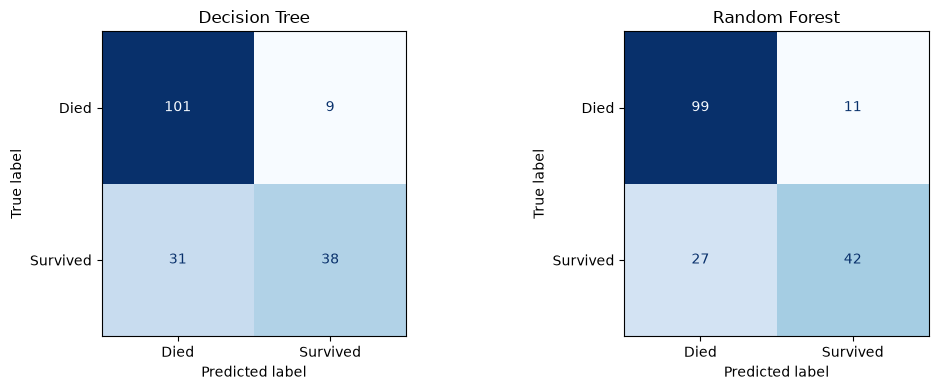

,CV accuracy,Train accuracy,Test accuracy,Precision,Recall,F1,ROC-AUC,Fit seconds
Model,,,,,,,,
Decision Tree,0.8118,0.8357,0.7765,0.8085,0.5507,0.6552,0.8182,0.0137
Random Forest,0.8146,0.8975,0.7877,0.7925,0.6087,0.6885,0.8397,0.4558


Baseline đoán lớp phổ biến theo train: 0.6145251396648045


In [5]:
rows = []
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (name, model) in zip(axes, models.items()):
    start = time.perf_counter()
    model.fit(X_train, y_train)
    fit_seconds = time.perf_counter() - start
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]
    rows.append({
        'Model': name,
        'CV accuracy': cv_results[name][0],
        'Train accuracy': model.score(X_train, y_train),
        'Test accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred, zero_division=0),
        'Recall': recall_score(y_test, y_pred, zero_division=0),
        'F1': f1_score(y_test, y_pred, zero_division=0),
        'ROC-AUC': roc_auc_score(y_test, y_prob),
        'Fit seconds': fit_seconds
    })
    print('\n' + name)
    print(classification_report(y_test, y_pred, labels=[0, 1],
          target_names=['Khong song sot', 'Song sot'], zero_division=0))
    ConfusionMatrixDisplay.from_predictions(
        y_test, y_pred, labels=[0, 1], display_labels=['Died', 'Survived'],
        cmap='Blues', colorbar=False, ax=ax)
    ax.set_title(name)
plt.tight_layout()
plt.show()
results = pd.DataFrame(rows).set_index('Model')
display(results.round(4))
print('Baseline đoán lớp phổ biến theo train:', accuracy_score(
    y_test, np.full(len(y_test), y_train.mode().iloc[0])))

## 5. Vẽ cây quyết định
Điều kiện đúng: sang nhánh trái; sai: sang nhánh phải. 

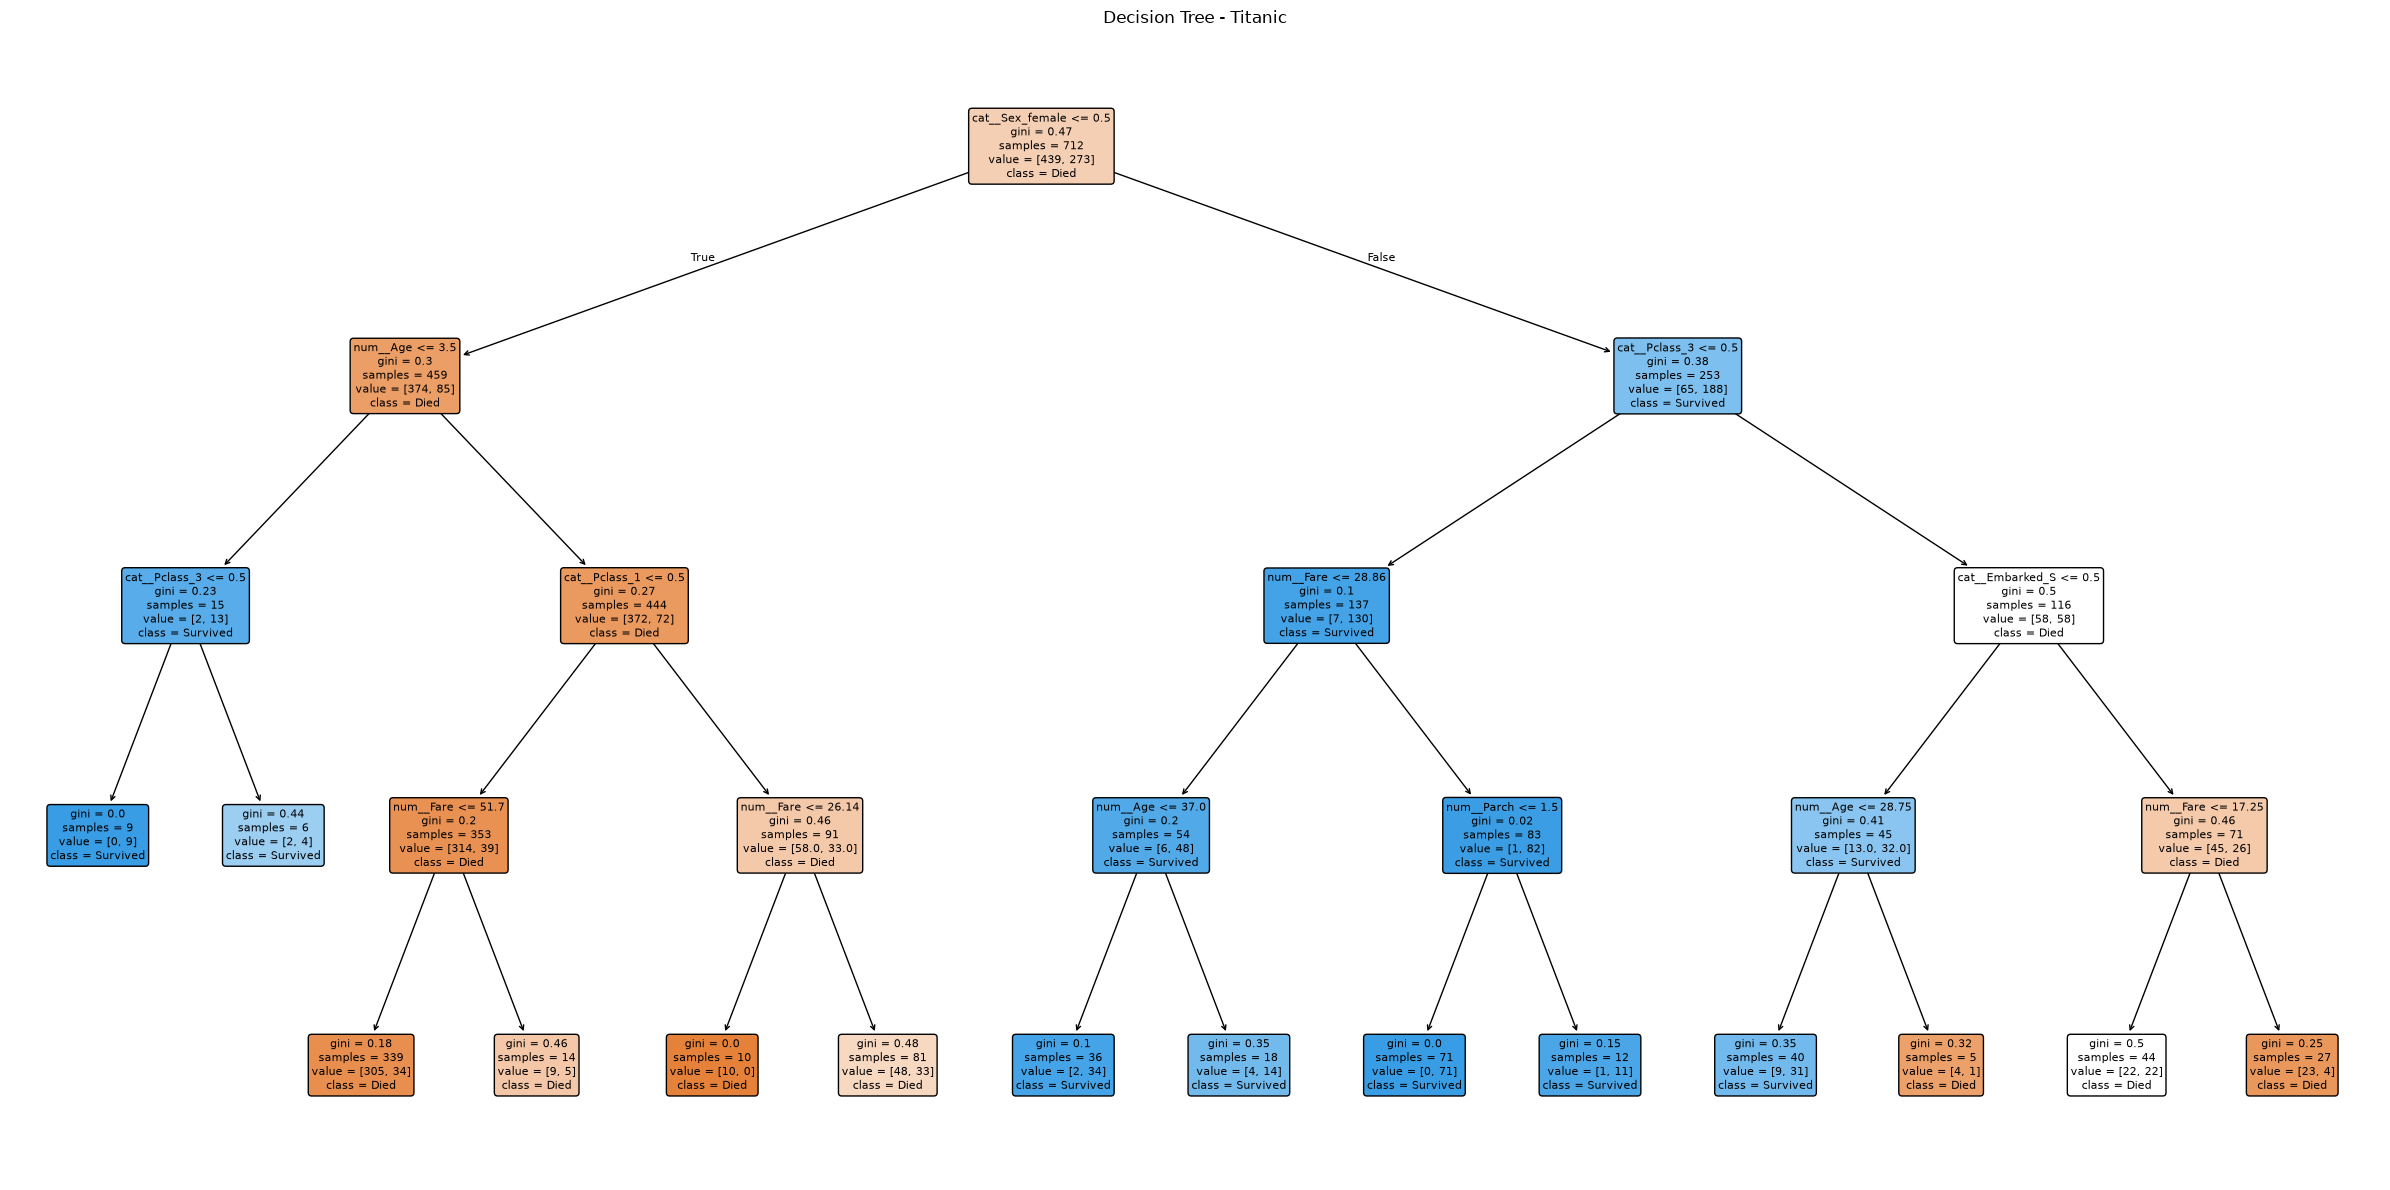

|--- cat__Sex_female <= 0.50
|   |--- num__Age <= 3.50
|   |   |--- cat__Pclass_3 <= 0.50
|   |   |   |--- class: 1
|   |   |--- cat__Pclass_3 >  0.50
|   |   |   |--- class: 1
|   |--- num__Age >  3.50
|   |   |--- cat__Pclass_1 <= 0.50
|   |   |   |--- num__Fare <= 51.70
|   |   |   |   |--- class: 0
|   |   |   |--- num__Fare >  51.70
|   |   |   |   |--- class: 0
|   |   |--- cat__Pclass_1 >  0.50
|   |   |   |--- num__Fare <= 26.14
|   |   |   |   |--- class: 0
|   |   |   |--- num__Fare >  26.14
|   |   |   |   |--- class: 0
|--- cat__Sex_female >  0.50
|   |--- cat__Pclass_3 <= 0.50
|   |   |--- num__Fare <= 28.86
|   |   |   |--- num__Age <= 37.00
|   |   |   |   |--- class: 1
|   |   |   |--- num__Age >  37.00
|   |   |   |   |--- class: 1
|   |   |--- num__Fare >  28.86
|   |   |   |--- num__Parch <= 1.50
|   |   |   |   |--- class: 1
|   |   |   |--- num__Parch >  1.50
|   |   |   |   |--- class: 1
|   |--- cat__Pclass_3 >  0.50
|   |   |--- cat__Embarked_S <= 0.50
|   |   |

In [6]:
dt = models['Decision Tree']
feature_names = dt.named_steps['preprocess'].get_feature_names_out()
plt.figure(figsize=(24, 12))
plot_tree(dt.named_steps['model'], feature_names=feature_names,
          class_names=['Died', 'Survived'], filled=True, rounded=True,
          fontsize=8, precision=2)
plt.title('Decision Tree - Titanic')
plt.tight_layout()
plt.show()
print(export_text(dt.named_steps['model'], feature_names=list(feature_names)))

## 6. Xem một cây trong rừng và độ quan trọng đặc trưng
Một rừng có nhiều cây nên không vẽ toàn bộ rừng trên cùng hình. Dưới đây là ba tầng đầu của cây đầu tiên.

Feature importance dựa trên mức giảm impurity, không chứng minh quan hệ nhân quả và có thể thiên lệch về các đặc trưng có nhiều giá trị khác nhau.

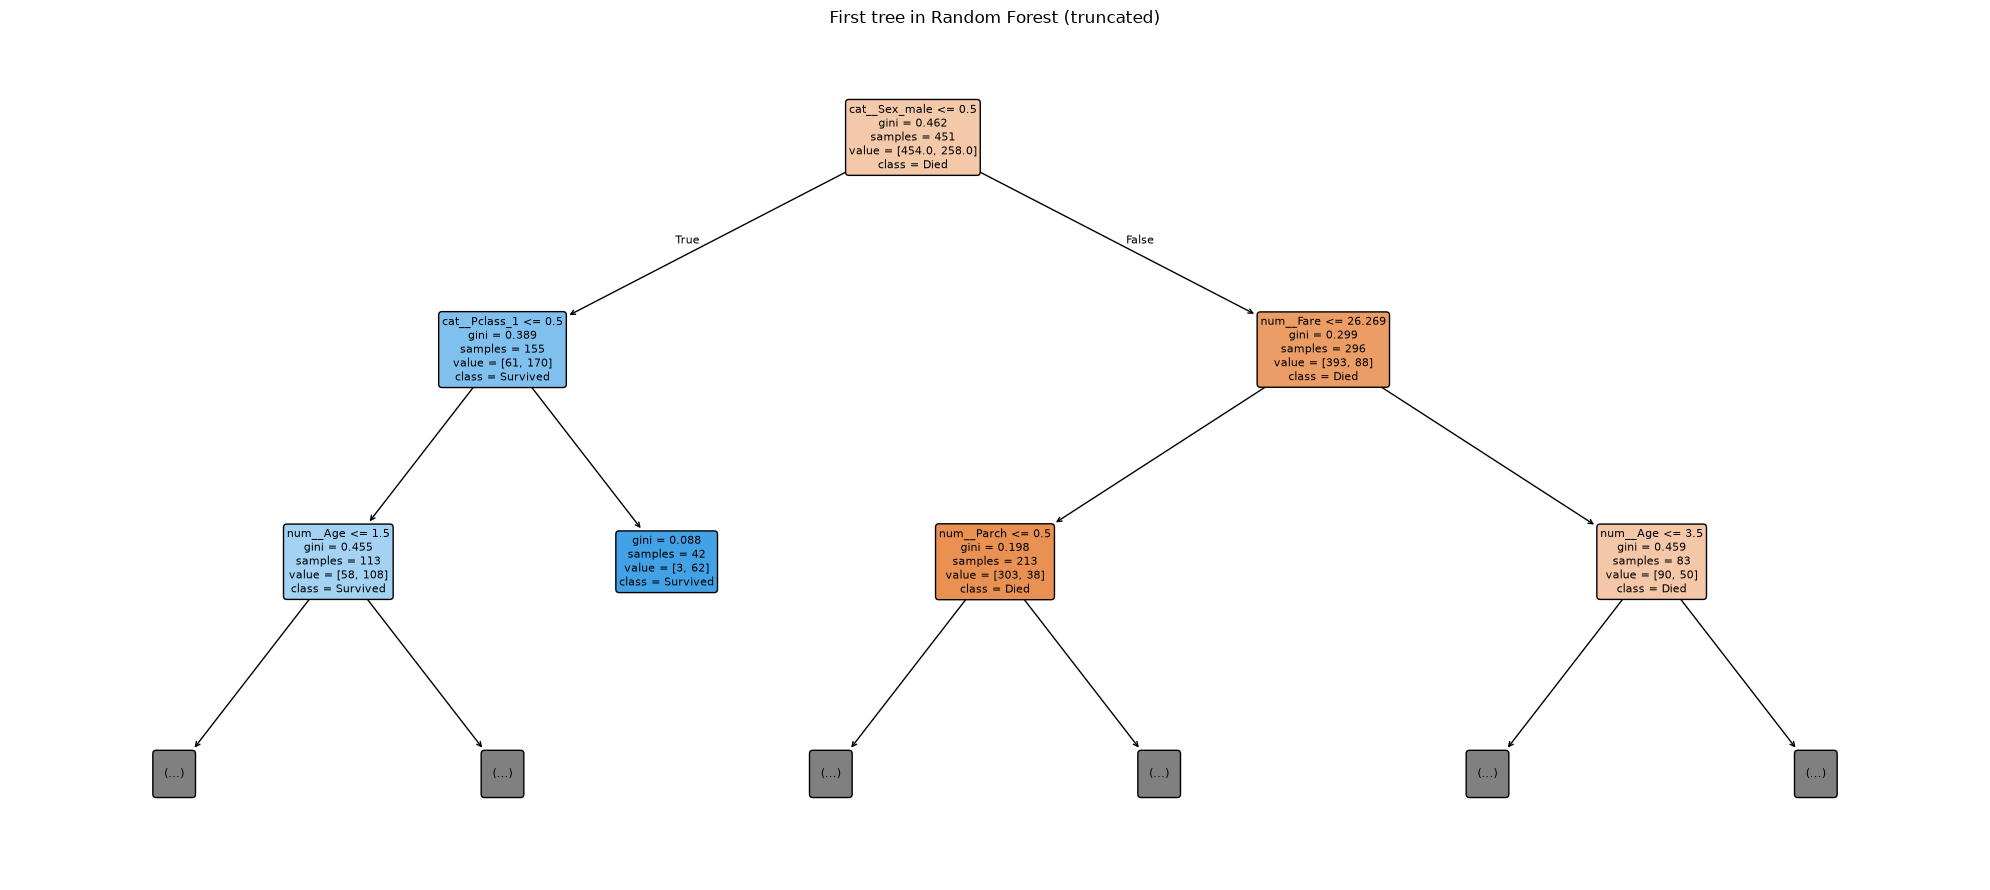

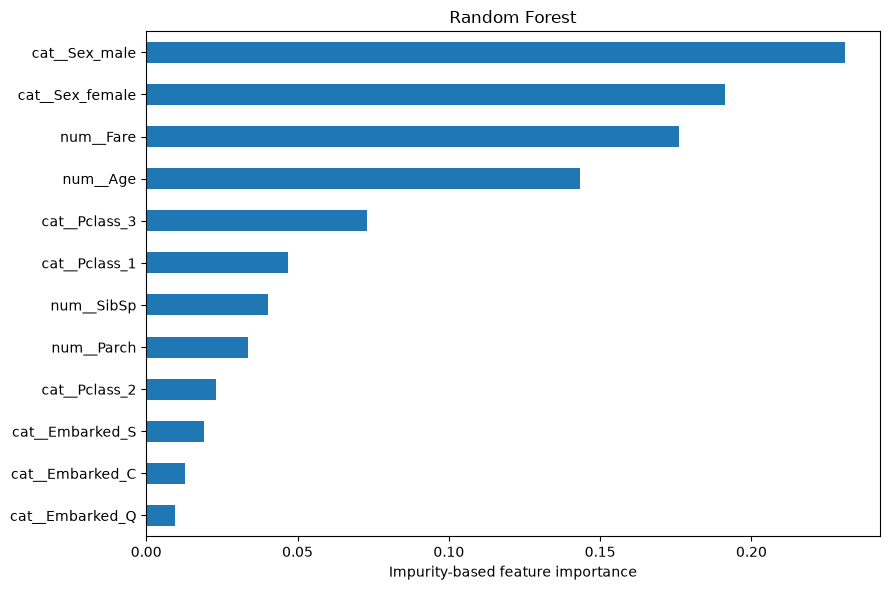

,Importance
cat__Sex_male,0.230930
cat__Sex_female,0.191201
num__Fare,0.176110
num__Age,0.143233
cat__Pclass_3,0.073035
cat__Pclass_1,0.047006
num__SibSp,0.040121
num__Parch,0.033755
cat__Pclass_2,0.022919
cat__Embarked_S,0.019065


In [7]:
rf = models['Random Forest']
rf_names = rf.named_steps['preprocess'].get_feature_names_out()
plt.figure(figsize=(20, 9))
plot_tree(rf.named_steps['model'].estimators_[0], feature_names=rf_names,
          class_names=['Died', 'Survived'], max_depth=2,
          filled=True, rounded=True, fontsize=8)
plt.title('First tree in Random Forest (truncated)')
plt.tight_layout()
plt.show()
importance = pd.Series(rf.named_steps['model'].feature_importances_, index=rf_names)
importance.sort_values().plot.barh(figsize=(9, 6))
plt.xlabel('Impurity-based feature importance')
plt.title('Random Forest')
plt.tight_layout()
plt.show()
display(importance.sort_values(ascending=False).to_frame('Importance'))

## 7. Dự đoán cho hành khách mới
Dùng mô hình đã chọn theo cross-validation. Xác suất chỉ là ước lượng của mô hình.

In [8]:
new_passengers = pd.DataFrame([
    {'Age': 25, 'SibSp': 0, 'Parch': 0, 'Fare': 80,
     'Pclass': 1, 'Sex': 'female', 'Embarked': 'S'},
    {'Age': 30, 'SibSp': 0, 'Parch': 0, 'Fare': 8,
     'Pclass': 3, 'Sex': 'male', 'Embarked': 'S'}
])[features]
selected_model = models[selected_name]
predictions = new_passengers.copy()
predictions['Predicted_Survived'] = selected_model.predict(new_passengers)
predictions['Survival_probability'] = selected_model.predict_proba(new_passengers)[:, 1]
display(predictions)

,Age,SibSp,Parch,Fare,Pclass,Sex,Embarked,Predicted_Survived,Survival_probability
0,25,0,0,80,1,female,S,1,0.960689
1,30,0,0,8,3,male,S,0,0.155149
